# Stock Buy Decision

Clean decision dashboard for one ticker.

In [3]:
TICKER = "BID"
BENCHMARK = "VNINDEX"
CONFIG_PATH = "../config.yaml"

In [4]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd()
ENGINE_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else Path("stock-decision-engine").resolve()
PROJECT_ROOT = ENGINE_ROOT.parent
SRC = ENGINE_ROOT / "src"
for p in [str(SRC), str(PROJECT_ROOT)]:
    if p not in sys.path:
        sys.path.insert(0, p)

from data import load_config, load_stock_ohlcv, load_benchmark_ohlcv, load_backtest_evidence
from features import enrich
from simulation import bootstrap_monte_carlo
from scoring import score_decision
from report import decision_summary, save_outputs
from visualization import save_all_charts

## Load Data

In [6]:
cfg_path = (ENGINE_ROOT / "notebooks" / CONFIG_PATH).resolve()
cfg = load_config(cfg_path, PROJECT_ROOT)
cfg["ticker"] = TICKER
cfg["benchmark"] = BENCHMARK

stock = load_stock_ohlcv(TICKER, PROJECT_ROOT, cfg["lookback_days"])
benchmark = load_benchmark_ohlcv(BENCHMARK, PROJECT_ROOT, cfg["lookback_days"])
backtest = load_backtest_evidence(TICKER, PROJECT_ROOT)

print(f"Loaded {len(stock):,} stock rows and {len(benchmark):,} benchmark rows.")

Loaded 756 stock rows and 756 benchmark rows.


## Features, Simulation, Score

In [8]:
stock_f, benchmark_f, relative_strength, rolling_alpha_beta, metrics = enrich(stock, benchmark, cfg)
mc = bootstrap_monte_carlo(stock_f, metrics, cfg)
decision = score_decision(metrics, mc.summary, backtest, cfg)

decision["sub_scores"]

/opt/anaconda3/envs/vnquant/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:377: RuntimeWarning: invalid value encountered in cast
  new_result = trans(result).astype(dtype)
/opt/anaconda3/envs/vnquant/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:377: RuntimeWarning: invalid value encountered in cast
  new_result = trans(result).astype(dtype)


,component,score,weight,reason
0,market_regime,100.0,10,"Benchmark trend, slope, returns, drawdown, and..."
1,trend,50.0,20,"MA structure, slopes, ADX/+DI, and breakout co..."
2,momentum,71.0,15,"Multi-horizon returns, RSI, MACD, and accelera..."
3,relative_strength,25.0,15,"Excess return, RS slope, beta, and correlation."
4,alpha,71.0,15,"CAPM alpha, Sharpe/Sortino/IR/Calmar, and opti..."
5,risk,65.0,10,"ATR, volatility percentile, drawdown, CVaR, sk..."
6,liquidity,93.0,10,"Average value, volume participation, z-score, ..."
7,simulation,28.0,5,"Bootstrap probability, expected return, and si..."


## Dashboard Charts

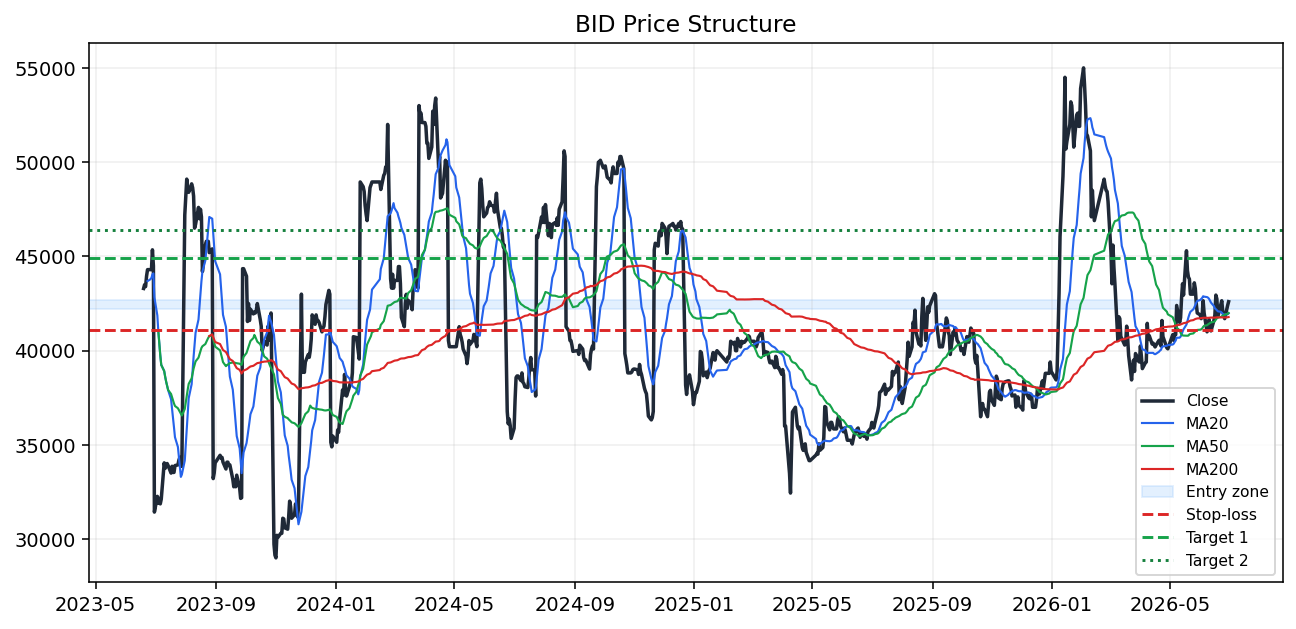

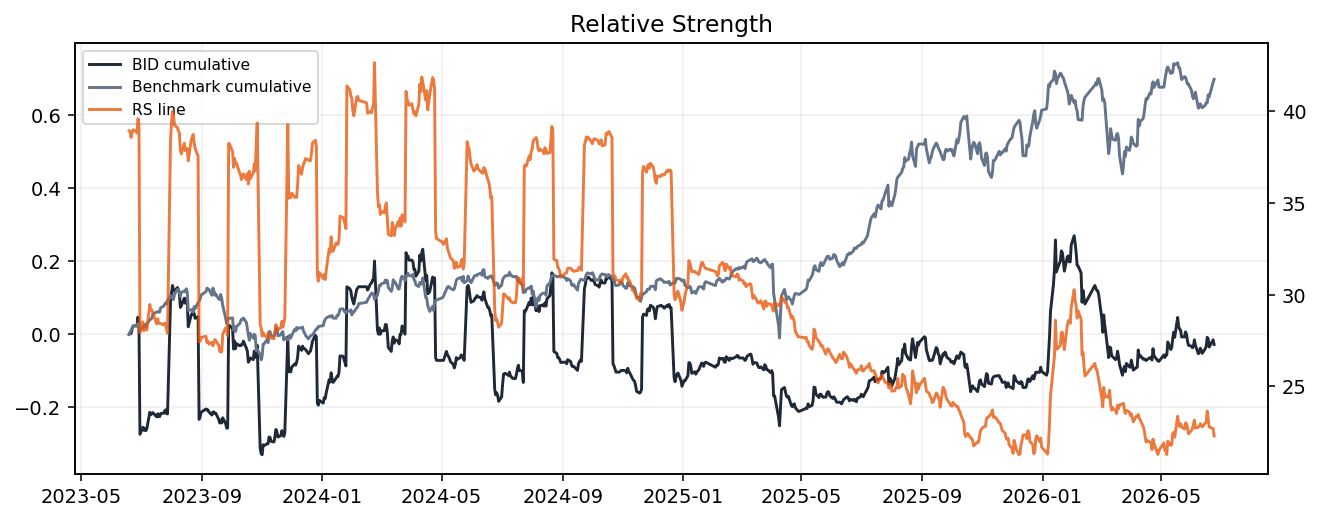

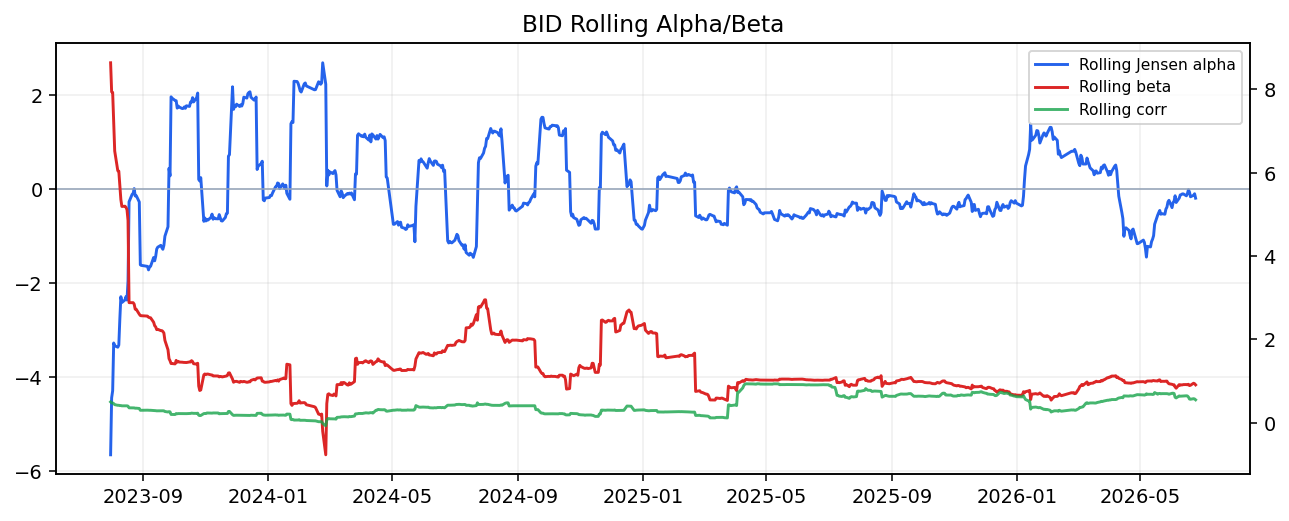

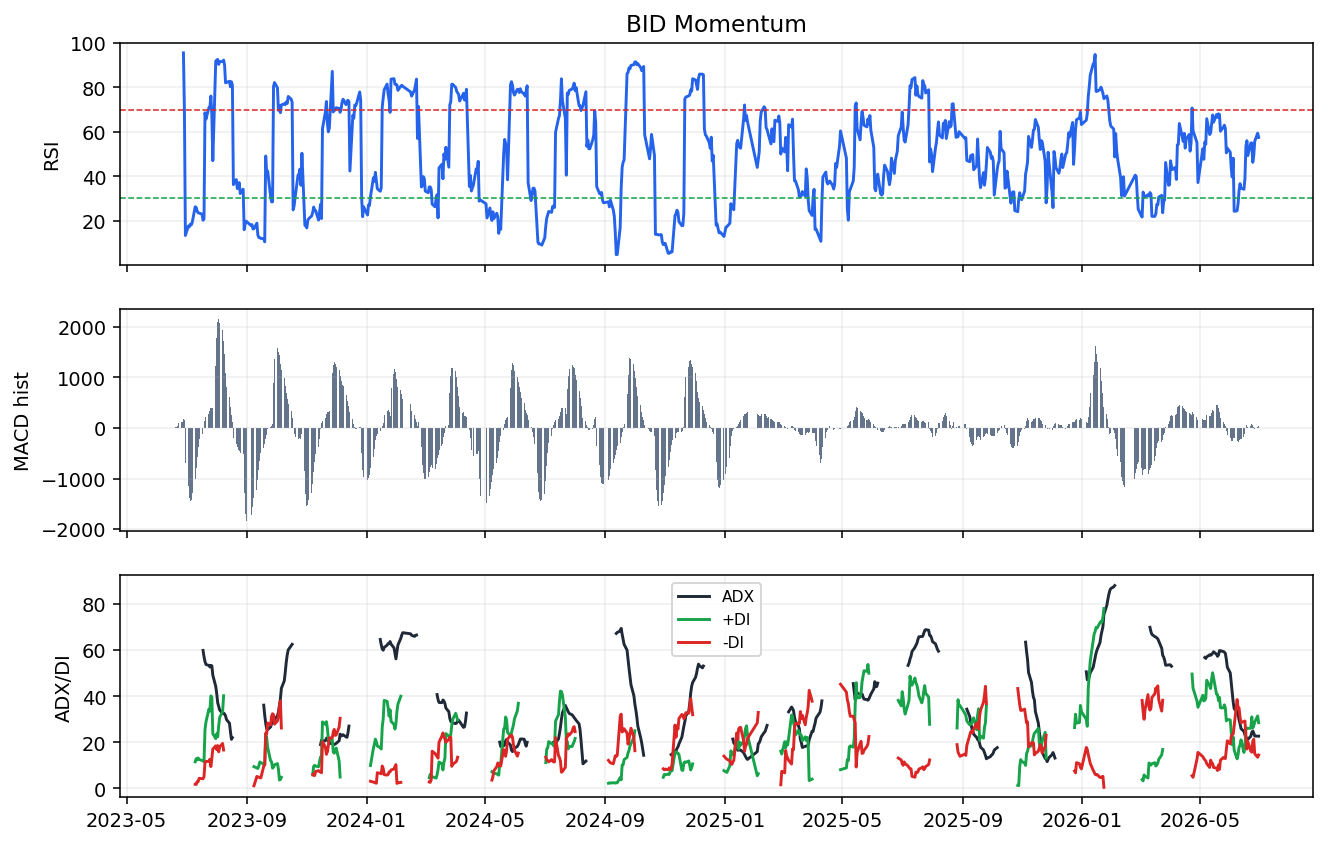

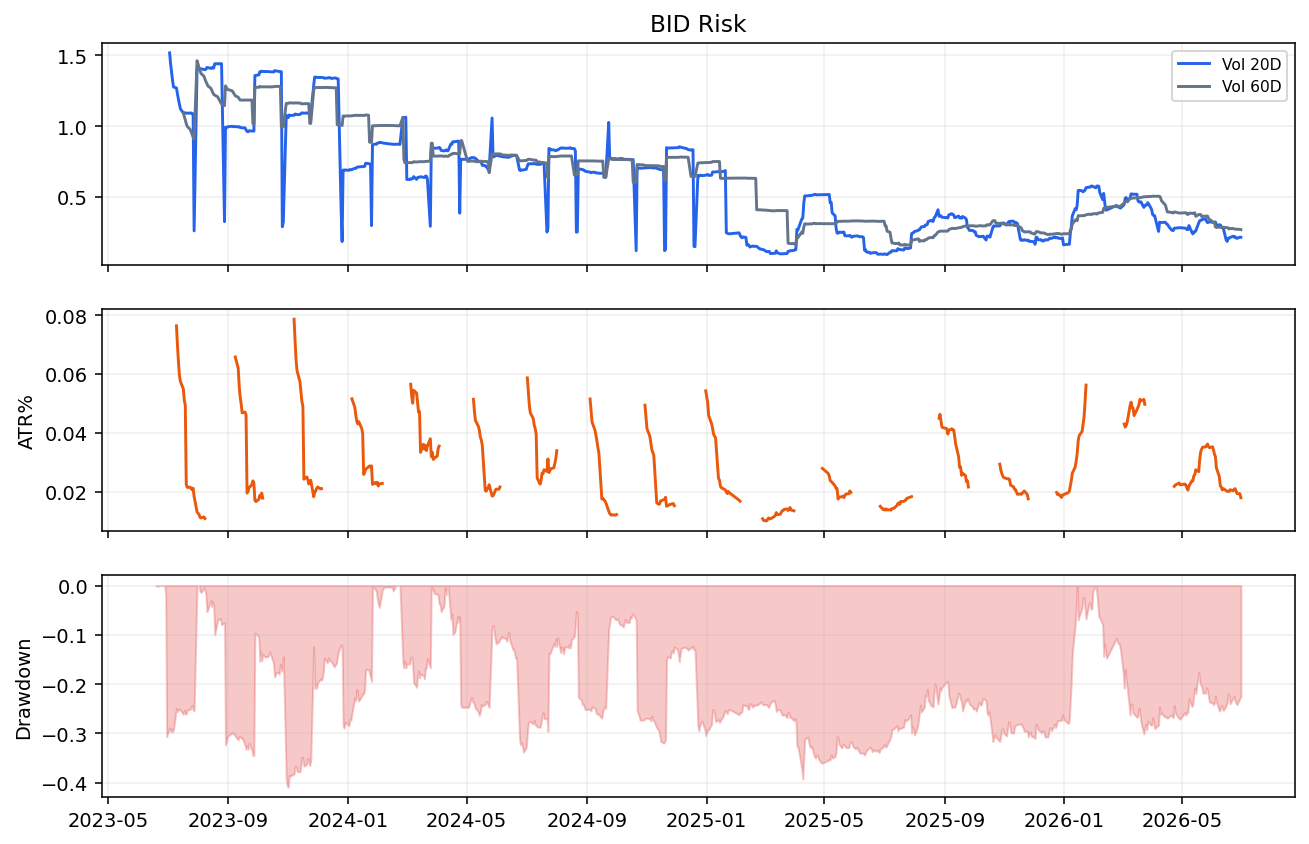

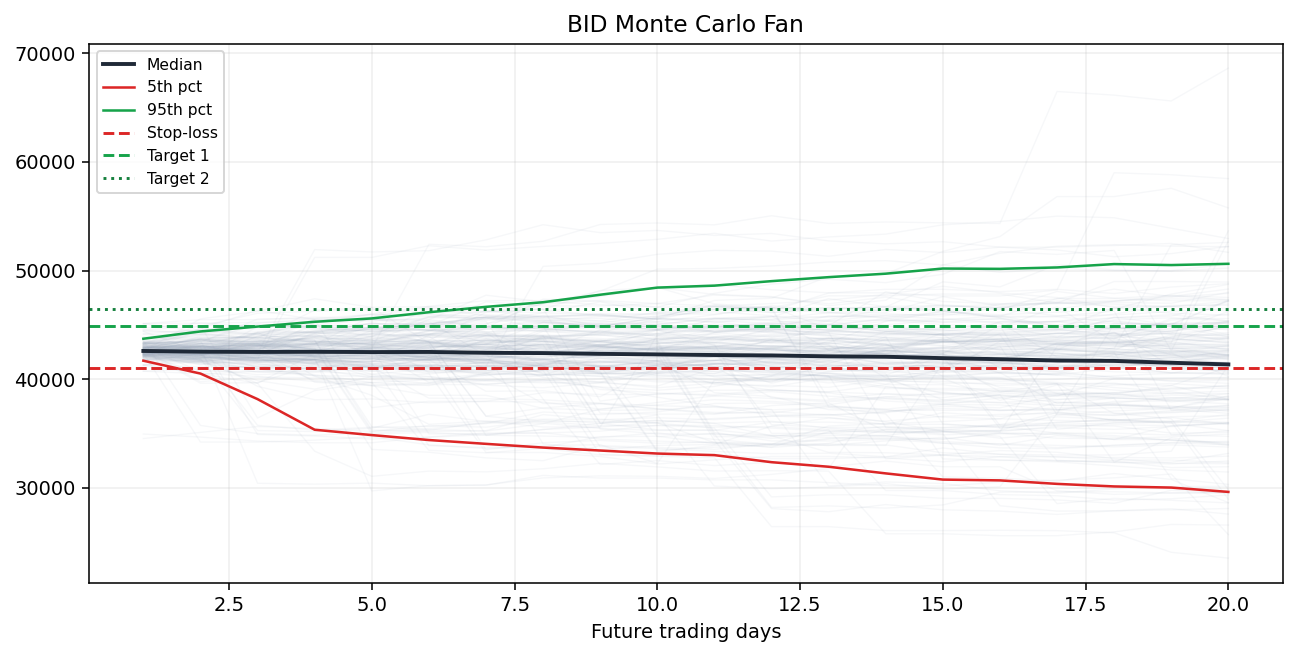

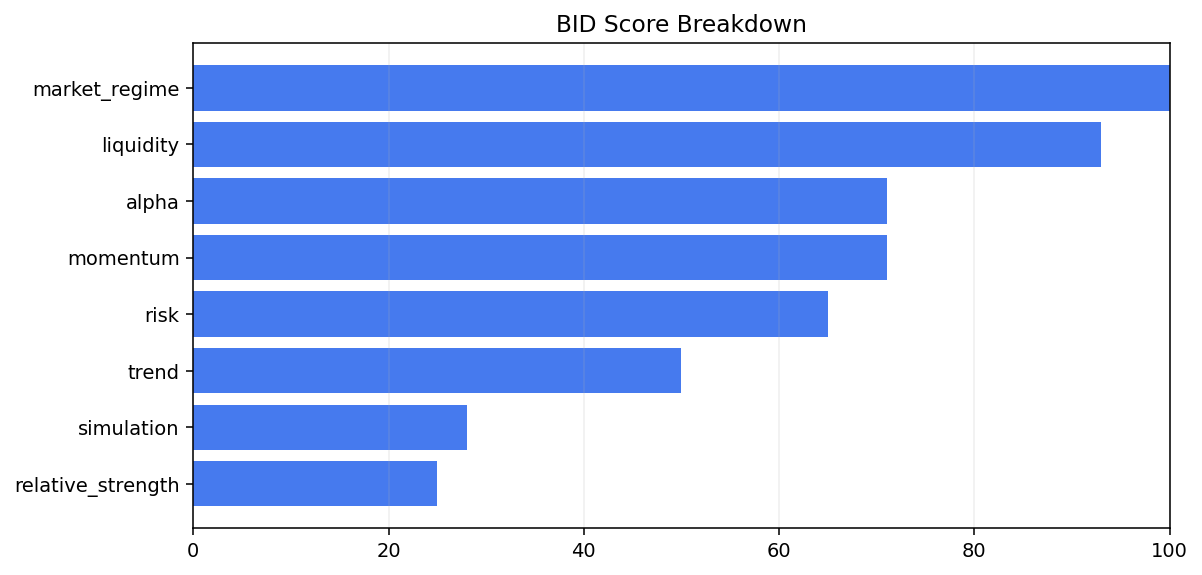

{'price_structure': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_price_structure.png'),
 'relative_strength': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_relative_strength.png'),
 'rolling_alpha_beta': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_rolling_alpha_beta.png'),
 'momentum': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_momentum.png'),
 'risk': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_risk.png'),
 'monte_carlo_fan': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_monte_carlo_fan.png'),
 'score_breakdown': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_score_breakdown.png')}

In [10]:
outputs_dir = ENGINE_ROOT / "outputs"
from IPython.display import Image, display

chart_paths = save_all_charts(
    stock_f,
    benchmark_f,
    relative_strength,
    rolling_alpha_beta,
    mc.paths,
    metrics,
    decision,
    outputs_dir,
    TICKER,
)
for path in chart_paths.values():
    display(Image(filename=str(path)))
chart_paths

## Final Decision

In [12]:
saved = save_outputs(outputs_dir, TICKER, metrics, decision, mc.summary, backtest)
summary = decision_summary(TICKER, metrics, decision, mc.summary)
print(summary)
saved

Ticker: BID
Date: 2026-06-30

Final Score: 62/100
Decision: WATCH / WAIT FOR PULLBACK
Confidence: Medium

Entry Zone: 42,218 - 42,696
Stop-loss: 41,071
Target 1: 44,893
Target 2: 46,421
Risk/Reward: 1.50

Market Regime: Bullish
Trend: Mixed
Momentum: Positive
Relative Strength: Neutral/lagging
Alpha: 0.76%
Risk: Controlled
Liquidity: Passed
Simulation: 31.6% target-before-stop probability

Main Reasons:
1. market_regime: 100/100 - Benchmark trend, slope, returns, drawdown, and volatility.
2. liquidity: 93/100 - Average value, volume participation, z-score, MFI, and CMF.
3. momentum: 71/100 - Multi-horizon returns, RSI, MACD, and acceleration.

Warnings:
1. Risk/reward is below the preferred buy threshold.
2. Monte Carlo paths hit stop before target more often than the reverse.

Vietnamese Broker Note:
BID hiện được hệ thống chấm 62/100 với khuyến nghị WATCH / WAIT FOR PULLBACK. Bối cảnh thị trường chung đang ở trạng thái bullish, còn xu hướng của cổ phiếu là mixed. Giá vẫn giữ trên MA5

{'summary': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_2026-06-30_decision_summary.txt'),
 'scores': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_2026-06-30_sub_scores.csv'),
 'metrics': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/BID_2026-06-30_metrics.csv')}